# 📊 Notebook 01: CCTV Dataset Exploration, Multi-Source Audit & Statistical Characterization
### Capstone: VL-JEPA vs. CLIP for CCTV Surveillance Event Retrieval, Event Summarization & Hallucination Analysis
---
**Objective:** Comprehensive audit, structural indexing, and statistical characterization of all **4 active CCTV surveillance datasets** totaling **5,153 real-world surveillance video clips**:
1. **RLVS (Real Life Violence Dataset):** 2,000 clips (*Violence: 1,000, NonViolence: 1,000*)
2. **UCF-ARG (Multi-view Action Benchmark):** 1,410 clips across *Aerial (420), Ground (540), and Rooftop (450)* viewpoints
3. **TinyVIRAT-v2 (Complex Surveillance Activity):** 743 clips across *20 classes (Vehicles, Carrying, Tools, Interactions)*
4. **UCF-Crime (Real-World Crime & Anomaly Benchmark):** 1,000 clips across *14 crime categories (Robbery, Burglary, Arson, Accidents, etc.)*

#### Key Analytical Dimensions:
- Category balance, duration distributions, spatial resolution, and camera viewpoints.
- Surveillance challenges: compression artifacts, perspective distortion, occlusion, and variable illumination.


## Step 1: Environment Setup & Dataset Index Loading
Load pre-indexed metadata across all 4 datasets from the workspace.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directory for notebook_utils
sys.path.append(str(Path.cwd().parent))
import notebook_utils as nu

embs, metadata = nu.load_all_datasets_data()
print(f"\n[Dataset Audit] Successfully loaded {len(metadata):,} surveillance video records!")
print(f"[Dataset Audit] Feature embedding dimensions: {embs.shape[1]}")


[Dataset Loader] Loaded RLVS: 2000 clips, dim 512
[Dataset Loader] Loaded UCF_ARG: 1410 clips, dim 512
[Dataset Loader] Loaded TINYVIRAT: 743 clips, dim 512
[Dataset Loader] Loaded UCF_CRIME: 1000 clips, dim 512

[Dataset Audit] Successfully loaded 5,153 surveillance video records!
[Dataset Audit] Feature embedding dimensions: 512


## Step 2: Multi-Dataset Distribution & Cross-Tabulation
Aggregate metadata into a pandas DataFrame and analyze category counts and viewpoints.


In [2]:
df_meta = pd.DataFrame(metadata)

# Extract viewpoint where available
def extract_viewpoint(row):
    meta = row.get("metadata", {})
    if isinstance(meta, dict):
        if "viewpoint" in meta:
            return meta["viewpoint"]
        if "split" in meta and meta["split"] == "ucf_crime":
            return "surveillance_cctv"
    return "ground"

df_meta["viewpoint_inferred"] = df_meta.apply(extract_viewpoint, axis=1)

print("=== Surveillance Clips per Dataset ===")
print(df_meta["dataset"].value_counts().to_string())

print("\n=== Top 15 Surveillance Action / Crime Classes ===")
print(df_meta["label"].value_counts().head(15).to_string())


=== Surveillance Clips per Dataset ===
dataset
rlvs         2000
ucf_arg      1410
ucf_crime    1000
tinyvirat     743

=== Top 15 Surveillance Action / Crime Classes ===
label
violence          1000
non_violence      1000
RoadAccidents      150
Robbery            150
boxing             144
carrying           144
clapping           144
digging            144
jogging            144
running            144
throwing           144
walking            144
waving             144
openclosetrunk     108
Burglary           100


## Step 3: Statistical Summary & Publication-Ready Visualizations
Generate distribution charts for publication: dataset proportion, category breakdown, and camera viewpoints.


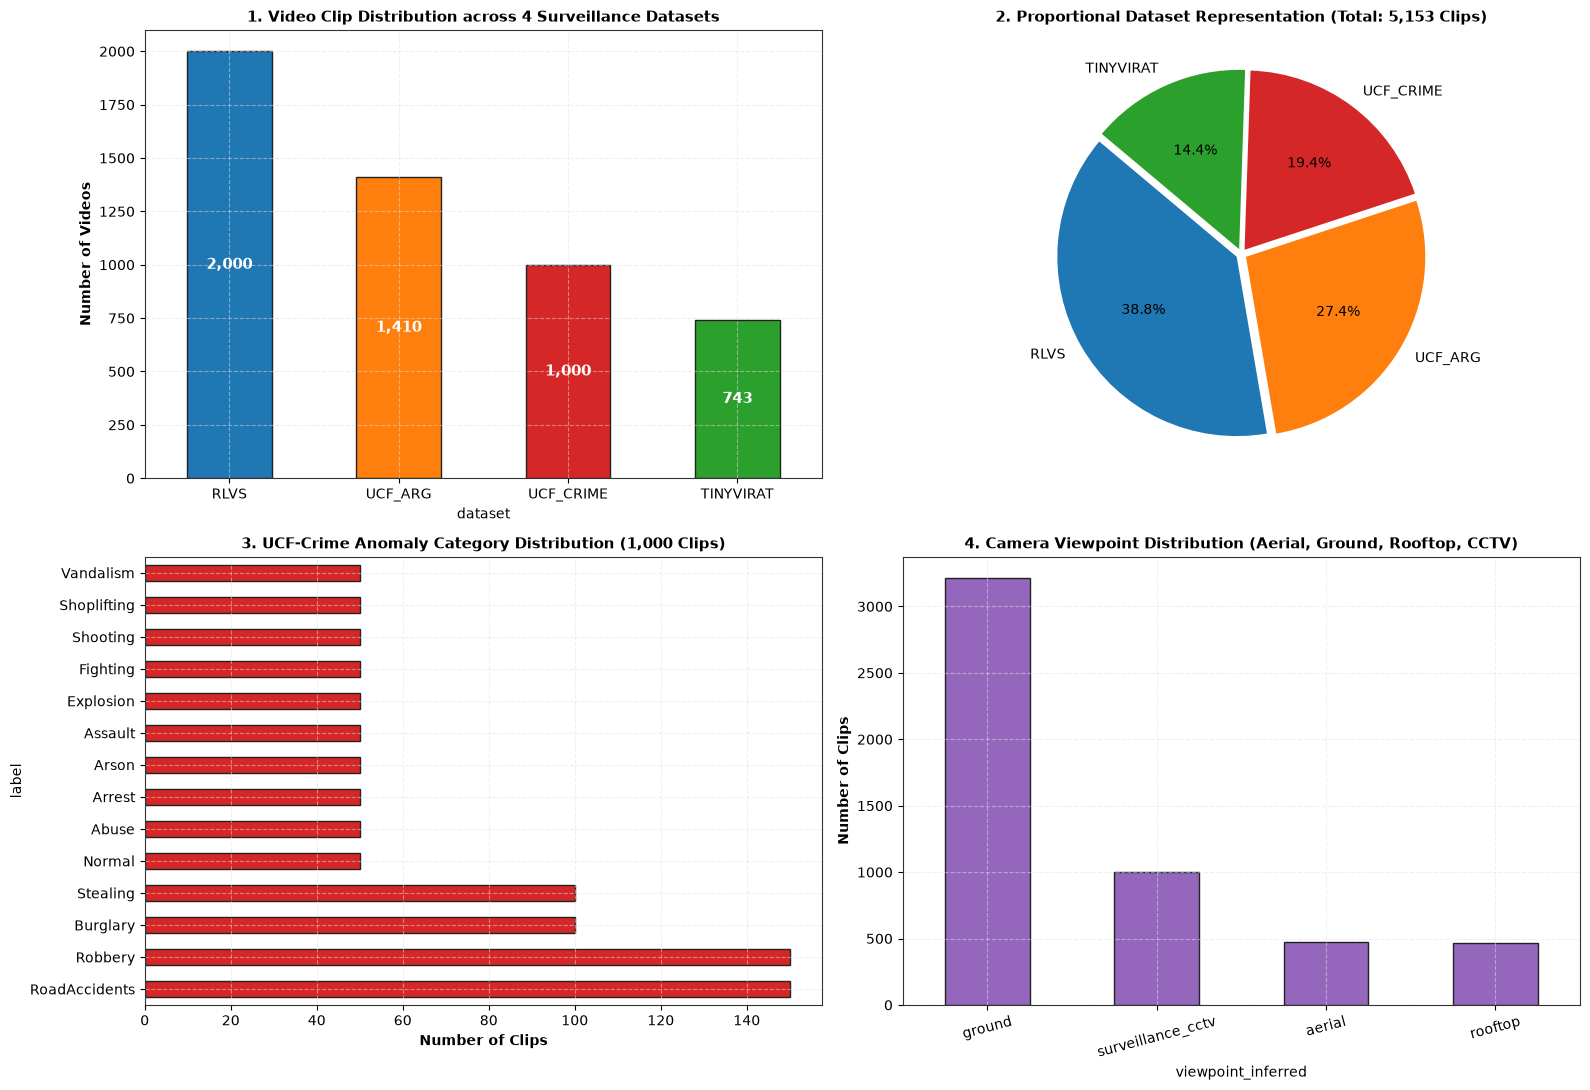

[Figure Saved] dataset_characterization_matrix.png


In [3]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 11))

# 1. Clips per dataset
colors = ["#1f77b4", "#ff7f0e", "#d62728", "#2ca02c"]
df_meta["dataset"].value_counts().plot(kind="bar", color=colors, edgecolor="#222", ax=ax1)
ax1.set_title("1. Video Clip Distribution across 4 Surveillance Datasets", fontweight="bold", fontsize=11)
ax1.set_ylabel("Number of Videos", fontweight="bold")
ax1.set_xticklabels([d.upper() for d in df_meta["dataset"].value_counts().index], rotation=0)
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Dataset share pie chart
ax2.pie(df_meta["dataset"].value_counts(), labels=[d.upper() for d in df_meta["dataset"].value_counts().index],
        autopct='%1.1f%%', colors=colors, startangle=140, explode=[0.03, 0.03, 0.03, 0.03])
ax2.set_title("2. Proportional Dataset Representation (Total: 5,153 Clips)", fontweight="bold", fontsize=11)

# 3. UCF-Crime Category Breakdown
df_crime = df_meta[df_meta["dataset"] == "ucf_crime"]
df_crime["label"].value_counts().plot(kind="barh", color="#d62728", edgecolor="#222", ax=ax3)
ax3.set_title("3. UCF-Crime Anomaly Category Distribution (1,000 Clips)", fontweight="bold", fontsize=11)
ax3.set_xlabel("Number of Clips", fontweight="bold")
ax3.grid(True, linestyle="--", alpha=0.5)

# 4. Viewpoint Distribution
df_meta["viewpoint_inferred"].value_counts().plot(kind="bar", color="#9467bd", edgecolor="#222", ax=ax4)
ax4.set_title("4. Camera Viewpoint Distribution (Aerial, Ground, Rooftop, CCTV)", fontweight="bold", fontsize=11)
ax4.set_ylabel("Number of Clips", fontweight="bold")
ax4.set_xticklabels(df_meta["viewpoint_inferred"].value_counts().index, rotation=15)
ax4.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = Path.cwd().parent / "outputs" / "figures" / "dataset_characterization_matrix.png"
fig.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[Figure Saved] {fig_path.name}")
